<a href="https://colab.research.google.com/github/amanpoonia/SBeta_preparation/blob/main/Backtesting/WF_fundamentals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
'''
AIM: Understand walkforward framework Test settings &
Performance metrics for backtesting

Backtest a strategy(MA crossover : Long when when price closes above the moving average and short when it falls below)

'''

/tmp/ipykernel_301/3599741292.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download('^GSPC', start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


Price             Close         High          Low         Open      Volume
Ticker            ^GSPC        ^GSPC        ^GSPC        ^GSPC       ^GSPC
Date                                                                      
2020-01-02  3257.850098  3258.139893  3235.530029  3244.669922  3459930000
2020-01-03  3234.850098  3246.149902  3222.340088  3226.360107  3484700000
2020-01-06  3246.280029  3246.840088  3214.639893  3217.550049  3702460000
2020-01-07  3237.179932  3244.909912  3232.429932  3241.860107  3435910000
2020-01-08  3253.050049  3267.070068  3236.669922  3238.590088  3726840000


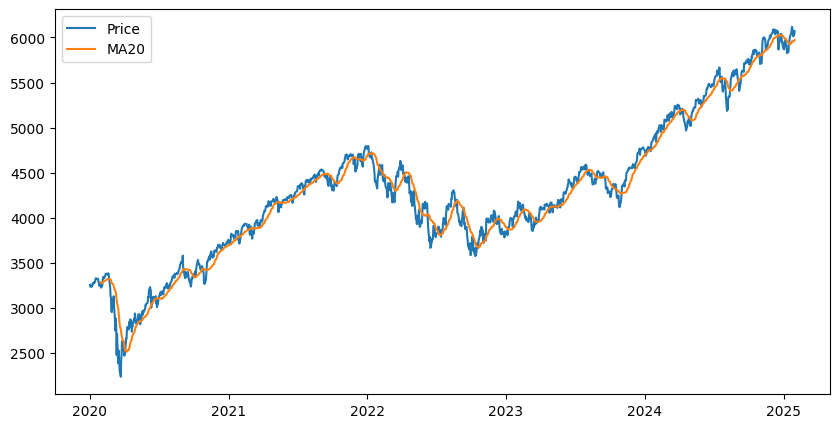

Ticker            ^GSPC         MA20  buy/sell
Date                                          
2020-01-02  3257.850098          NaN       NaN
2020-01-03  3234.850098          NaN       NaN
2020-01-06  3246.280029          NaN       NaN
2020-01-07  3237.179932          NaN       NaN
2020-01-08  3253.050049          NaN       NaN
2020-01-09  3274.699951          NaN       NaN
2020-01-10  3265.350098          NaN       NaN
2020-01-13  3288.129883          NaN       NaN
2020-01-14  3283.149902          NaN       NaN
2020-01-15  3289.290039          NaN       NaN
2020-01-16  3316.810059          NaN       NaN
2020-01-17  3329.620117          NaN       NaN
2020-01-21  3320.790039          NaN       NaN
2020-01-22  3321.750000          NaN       NaN
2020-01-23  3325.540039          NaN       NaN
2020-01-24  3295.469971          NaN       NaN
2020-01-27  3243.629883          NaN       NaN
2020-01-28  3276.239990          NaN       NaN
2020-01-29  3273.399902          NaN       NaN
2020-01-30  3

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

start_date = '2020-01-01'
end_date = '2025-01-31'

data = yf.download('^GSPC', start=start_date, end=end_date)
print(data.head())

#rolling average of the last 20 days
price = data['Close'].copy()

price['MA20'] = price['^GSPC'].rolling(20).mean()

#plotting MA with prices
plt.figure(figsize=(10, 5))
plt.plot(price['^GSPC'], label='Price')
plt.plot(price['MA20'], label='MA20')
plt.legend()
plt.show()


#trading, trades at crossover
price['buy/sell'] = np.where(price['^GSPC'] > price['MA20'], 1, -1).astype(float)
#price['sell'] = np.where(price['^GSPC'] < price['MA20'], 1, 0)
price.loc[price['MA20'].isna(), 'buy/sell'] = np.nan


print(price.head(21))

Ticker            ^GSPC         MA20  buy/sell  pos   prev_close       ret  \
Date                                                                         
2020-01-31  3225.520020  3279.220496      -1.0  1.0  3283.659912 -0.017864   
2020-02-03  3248.919922  3279.923987      -1.0 -1.0  3225.520020  0.007228   
2020-02-04  3297.590088  3282.489490       1.0 -1.0  3248.919922  0.014869   
2020-02-05  3334.689941  3287.364990       1.0  1.0  3297.590088  0.011188   
2020-02-06  3345.780029  3292.001489       1.0  1.0  3334.689941  0.003320   
2020-02-07  3327.709961  3294.651990       1.0  1.0  3345.780029 -0.005415   
2020-02-10  3352.090088  3298.988989       1.0  1.0  3327.709961  0.007300   
2020-02-11  3357.750000  3302.469995       1.0  1.0  3352.090088  0.001687   
2020-02-12  3379.449951  3307.284998       1.0  1.0  3357.750000  0.006442   
2020-02-13  3373.939941  3311.517493       1.0  1.0  3379.449951 -0.001632   

Ticker      ret_simple  ret_strat  cum_ret_strat  
Date        

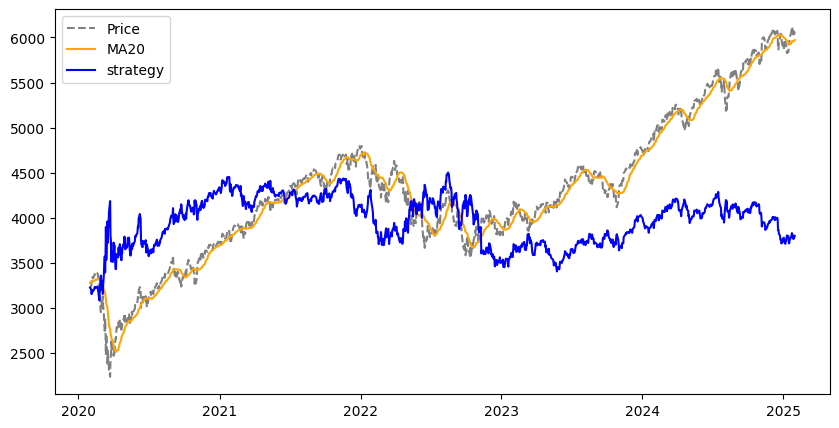

In [2]:
'''
Correctly aligning signal and return data

Signal is generated on time t
Trade(buy/sell) on time t
Held from time t to t+1
return on this trade at t+1.

ret_trade(t+1) = signal(t) * [P(t+1)-P(t)]/P(t)
'''

# position held over the day t
price['pos'] = price['buy/sell'].shift(1)

# entry price
price['prev_close'] = price['^GSPC'].shift(1)

# return of holding it for a day
price['ret'] = np.log(price['^GSPC']/price['prev_close'])
price['ret_simple'] = price['^GSPC'].pct_change()

#return of the strategy
price['ret_strat'] = np.log1p(price['pos'] * price['ret_simple'])

price.dropna(inplace=True)

# portfolio value
price['cum_ret_strat'] = price['prev_close'].iloc[0] * np.exp(price['ret_strat'].cumsum())
print(price.head(10))

plt.figure(figsize=(10, 5))
plt.plot(price['^GSPC'], label='Price', color = 'gray', linestyle = '--')
plt.plot(price['MA20'], label='MA20', color = 'orange')
plt.plot(price['cum_ret_strat'], label='strategy', color = 'blue')
plt.legend()
plt.show()

In [3]:
# metrics

price['pos_change'] = price['pos'] != price['pos'].shift(1)
price['trade_no'] = price['pos_change'].cumsum()
price['date'] = price.index

metrics = price.groupby('trade_no').agg(
    position = ('pos', 'first'),
    days_in_trade = ('trade_no', 'count'),
    ret_trade = ('ret_strat', 'sum'),
    entry_price = ('prev_close', 'first'),
    exit_price = ('^GSPC', 'last'),
    entry_date = ('date', 'first'),
    exit_date = ('date', 'last')
).reset_index(drop=True)

metrics['ret_simple_trade'] = np.expm1x(metrics['ret_trade'])
metrics['fixed_ret'] = metrics['position'] * (metrics['exit_price'] / metrics['entry_price'] - 1)
metrics

,position,days_in_trade,ret_trade,entry_price,exit_price,entry_date,exit_date,ret_simple_trade,fixed_ret
0,1.0,1,-0.017864,3283.659912,3225.520020,2020-01-31,2020-01-31,-0.017706,-0.017706
1,-1.0,2,-0.022375,3225.520020,3297.590088,2020-02-03,2020-02-04,-0.022126,-0.022344
2,1.0,13,-0.021983,3297.590088,3225.889893,2020-02-05,2020-02-24,-0.021743,-0.021743
3,-1.0,30,0.107465,3225.889893,2663.679932,2020-02-25,2020-04-06,0.113452,0.174281
4,1.0,26,0.057028,2663.679932,2820.000000,2020-04-07,2020-05-13,0.058686,0.058686
...,...,...,...,...,...,...,...,...,...
114,1.0,29,-0.009640,5929.040039,5872.160156,2024-11-07,2024-12-18,-0.009593,-0.009593
115,-1.0,4,-0.028482,5872.160156,6040.040039,2024-12-19,2024-12-24,-0.028080,-0.028589
116,1.0,2,-0.011523,6040.040039,5970.839844,2024-12-26,2024-12-27,-0.011457,-0.011457
117,-1.0,11,0.002482,5970.839844,5949.910156,2024-12-30,2025-01-15,0.002485,0.003505


In [18]:
# Performance
'''
See how long trades/short trades behaved
Their expected returns, average trading days, etc.
'''


long_trades = metrics[metrics['position'] == 1]
short_trades = metrics[metrics['position'] == -1]

print('PERFORMANCE METRICS')
print(f'Number of long trades: {len(long_trades)}')
print(f'Number of short trades: {len(short_trades)}')
print(f'avg length(days) in long trade: {long_trades['days_in_trade'].mean():.1f} days')
print(f'avg length(days) in short trade: {short_trades['days_in_trade'].mean():.1f} days')
print(f'ret from long: {long_trades['ret_simple_trade'].sum():.4f}')
print(f'ret from short: {short_trades['ret_simple_trade'].sum():.4f}')

PERFORMANCE METRICS
Number of long trades: 60
Number of short trades: 59
avg length(days) in long trade: 14.1 days
avg length(days) in short trade: 7.0 days
ret from long: 0.4915
ret from short: -0.2932


BELOW
NEXT COMPARE WITH SOME BENCHMARK OR BENCHMARK STRATEGY, like BUY AND HOLD

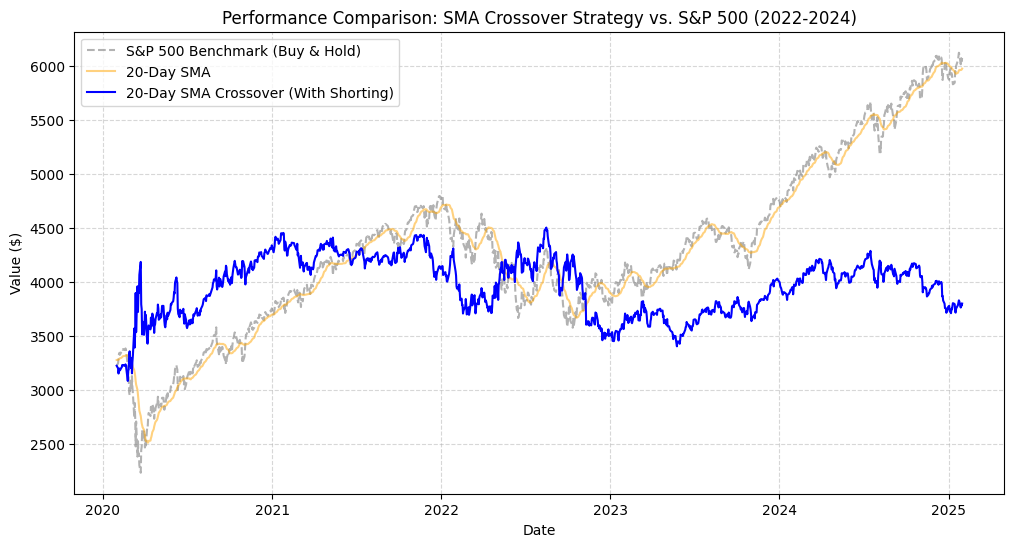

In [7]:


plt.figure(figsize=(12, 6))
# S&P 500 Benchmark (Buy & Hold from starting day)
plt.plot(price['^GSPC'], label='S&P 500 Benchmark (Buy & Hold)', color='gray', alpha=0.6, linestyle='--')
# 20-Day SMA Line
plt.plot(price['MA20'], label='20-Day SMA', color='orange', alpha=0.5)
# Cumulative Strategy Equity Curve (Starting at same initial index value)
plt.plot(price['cum_ret_strat'], label='20-Day SMA Crossover (With Shorting)', color='blue', linewidth=1.5)

plt.title('Performance Comparison: SMA Crossover Strategy vs. S&P 500 (2022-2024)')
plt.xlabel('Date')
plt.ylabel('Value ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [6]:
# Walk-Forward Optimization Framework
import pandas as pd
import numpy as np

def evaluate_strategy(df, sma_length):
    """Simulates the SMA crossover strategy and returns the total log return."""
    temp = df.copy()
    temp['MA'] = temp['^GSPC'].rolling(sma_length).mean()
    temp['signal'] = np.where(temp['^GSPC'] > temp['MA'], 1, -1)
    temp['ret'] = np.log(temp['^GSPC'] / temp['^GSPC'].shift(1))
    # Strategy returns based on previous day's signal
    temp['ret_strat'] = temp['signal'].shift(1) * temp['ret']
    return temp['ret_strat'].sum()

# Define parameter space to optimize
sma_candidates = [10, 20, 30, 50]

# We will use a sliding window approach:
# - In-Sample (IS) training window: 6 months
# - Out-of-Sample (OOS) testing window: 3 months

# Let's define the dates
dates = price.index
start_idx = 0
is_window_size = 126  # ~6 months of trading days
oos_window_size = 63  # ~3 months of trading days

oos_results = []

print("=== WALK-FORWARD RUNS ===")
while start_idx + is_window_size + oos_window_size < len(price):
    # Slice training (In-Sample) data
    is_data = price.iloc[start_idx : start_idx + is_window_size]
    # Slice testing (Out-of-Sample) data
    oos_data = price.iloc[start_idx + is_window_size : start_idx + is_window_size + oos_window_size].copy()

    # Step 1: Optimize parameter In-Sample
    best_sma = None
    best_is_return = -np.inf
    for sma in sma_candidates:
        is_ret = evaluate_strategy(is_data, sma)
        if is_ret > best_is_return:
            best_is_return = is_ret
            best_sma = sma

    # Step 2: Apply the best parameter Out-of-Sample
    # We calculate the OOS returns using the selected 'best_sma'
    oos_data['MA'] = oos_data['^GSPC'].rolling(best_sma).mean()
    oos_data['signal'] = np.where(oos_data['^GSPC'] > oos_data['MA'], 1, -1)
    oos_data['ret'] = np.log(oos_data['^GSPC'] / oos_data['^GSPC'].shift(1))
    oos_data['ret_strat'] = oos_data['signal'].shift(1) * oos_data['ret']

    oos_ret = oos_data['ret_strat'].sum()

    is_start_dt = is_data.index[0].strftime('%Y-%m-%d')
    is_end_dt = is_data.index[-1].strftime('%Y-%m-%d')
    oos_start_dt = oos_data.index[0].strftime('%Y-%m-%d')
    oos_end_dt = oos_data.index[-1].strftime('%Y-%m-%d')

    print(f"IS ({is_start_dt} to {is_end_dt}) -> Best SMA: {best_sma} (IS Ret: {best_is_return:.4f})")
    print(f"  -> OOS ({oos_start_dt} to {oos_end_dt}) -> Applied SMA {best_sma} (OOS Ret: {oos_ret:.4f})\n")

    oos_results.append(oos_data['ret_strat'])

    # Shift the window forward by the OOS step size
    start_idx += oos_window_size

# Combine all out-of-sample performance periods
if oos_results:
    all_oos_returns = pd.concat(oos_results).dropna()
    cum_oos_return = np.exp(all_oos_returns.cumsum()) - 1
    print(f"=== WALK-FORWARD OUT-OF-SAMPLE RESULTS ===")
    print(f"Cumulative Out-of-Sample Return: {cum_oos_return.iloc[-1]*100:.2f}%")


=== WALK-FORWARD RUNS ===
IS (2022-01-31 to 2022-08-01) -> Best SMA: 20 (IS Ret: 0.2025)
  -> OOS (2022-08-02 to 2022-10-28) -> Applied SMA 20 (OOS Ret: 0.0074)

IS (2022-05-02 to 2022-10-28) -> Best SMA: 30 (IS Ret: 0.2012)
  -> OOS (2022-10-31 to 2023-01-31) -> Applied SMA 30 (OOS Ret: -0.0583)

IS (2022-08-02 to 2023-01-31) -> Best SMA: 30 (IS Ret: 0.1196)
  -> OOS (2023-02-01 to 2023-05-02) -> Applied SMA 30 (OOS Ret: 0.0062)

IS (2022-10-31 to 2023-05-02) -> Best SMA: 20 (IS Ret: -0.0200)
  -> OOS (2023-05-03 to 2023-08-02) -> Applied SMA 20 (OOS Ret: 0.0552)

IS (2023-02-01 to 2023-08-02) -> Best SMA: 50 (IS Ret: 0.0783)
  -> OOS (2023-08-03 to 2023-10-31) -> Applied SMA 50 (OOS Ret: 0.0709)

=== WALK-FORWARD OUT-OF-SAMPLE RESULTS ===
Cumulative Out-of-Sample Return: 8.47%
